# II - Data Preparation & Preprocessing

The complete data preparation pipeline is implemented in `src/classification/prepare_data.py`. The function below validates the source data, creates the prepared split, loads the datasets, applies preprocessing and training-only augmentation, and returns the ready-to-use datasets.

## 1. Configuration and Preparation Strategy

Locate the project directories and display the preparation settings.

In [11]:
import importlib
import sys
from pathlib import Path
import warnings

sys.path.insert(0, str(Path.cwd().parents[1]))

import src.classification.prepare_data as prepare_data

prepare_data = importlib.reload(prepare_data)

from src.classification.prepare_data import (
    analyze_duplicates,
    remove_duplicates,
    augment_datasets,
    get_project_paths,
    load_datasets,
    organize_prepared_data,
    preprocess_datasets,
    print_configuration,
    validate_dataset_readiness,
    validate_files,
    visualize_preprocessed_images,
)
warnings.filterwarnings("ignore")

## 2. Duplicate Analysis and Data Leakage

Identify identical files before preparing the train and test directories.

In [12]:
paths = get_project_paths()
print_configuration(paths)
duplicate_groups = analyze_duplicates(paths["original_data_dir"])

Project root:      /home/houssam/Documents/brief-5
Original dataset:  /home/houssam/Documents/brief-5/Data/origine/classification
Prepared dataset:  /home/houssam/Documents/brief-5/Data/clean/classification_prepared
Image size:        (224, 224)
Batch size:        32
Validation split:  0.15
Duplicate groups: 194
Files in duplicate groups: 491

  Group 1 | SHA-256: 733e77e4b6da2d85…
    notumor/Te-no_0050.jpg
    notumor/Tr-no_0235.jpg
    notumor/Tr-no_0191.jpg
    notumor/Te-no_0045.jpg
    notumor/Te-no_0054.jpg
    notumor/Tr-no_0279.jpg

  Group 2 | SHA-256: 4c2c103442bacc20…
    notumor/Tr-no_0245.jpg
    notumor/Tr-no_1140.jpg

  Group 3 | SHA-256: b577189346bc4cc7…
    notumor/Te-no_0098.jpg
    notumor/Tr-no_0361.jpg

  Group 4 | SHA-256: 95ffabd6cfd94e09…
    notumor/Tr-no_0274.jpg
    notumor/Tr-no_1150.jpg

  Group 5 | SHA-256: 5b32b70fee5498a7…
    notumor/Tr-no_0222.jpg
    notumor/Tr-no_1104.jpg
    notumor/Tr-no_0344.jpg
    notumor/Tr-no_0148.jpg
    notumor/Te-no_0080.

## 3. Delete Duplicate Images

Keep one deterministic copy of each duplicate image and remove the remaining copies before validation.

In [13]:
# Collect all image paths from the original dataset
all_image_paths = sorted(
    p for p in paths["original_data_dir"].rglob("*")
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
)

print(f"Total images before deduplication: {len(all_image_paths)}")
unique_hashes, unique_images = remove_duplicates(all_image_paths)
print(f"Unique images after deduplication: {len(unique_images)}")
print(f"Duplicates removed: {len(all_image_paths) - len(unique_images)}")

Total images before deduplication: 7023
Unique images after deduplication: 6726
Duplicates removed: 297


## 4. Validate Files

Validate class directories, image readability, filename prefixes, and duplicate hashes.

In [14]:
manifest = validate_files(paths["original_data_dir"], image_paths=unique_images)


Valid images:                6726
Unsupported files:           0
Unreadable images:           0
Unrecognized prefixes:       0
Hashes spanning train/test:  0
Hashes spanning classes:     0


## 5. Organize Prepared Train/Test Data

Rebuild the generated directory from the validated manifest without modifying the original dataset.

In [15]:
organize_prepared_data(manifest, paths["prepared_data_dir"])

Prepared directories created successfully.
Original dataset was not modified.


## 6. Load Datasets

Create training, validation, and test datasets with a shared class mapping.

In [16]:
train_raw, val_raw, test_raw, class_names, class_mapping = load_datasets(
    paths["train_pool_dir"],
    paths["test_dir"],
)

Found 5521 files belonging to 4 classes.
Using 4693 files for training.
Found 5521 files belonging to 4 classes.
Using 828 files for validation.
Found 1205 files belonging to 4 classes.
Class-to-index mapping: {0: 'glioma', 1: 'meningioma', 2: 'notumor', 3: 'pituitary'}


## 7. Manual Image Preprocessing

Normalize image tensors to the `[0, 1]` range.

In [17]:
train_ds, val_ds, test_ds = preprocess_datasets(train_raw, val_raw, test_raw)

## 8. Visualize Preprocessed Images

Inspect one preprocessed training batch.

Images shape: (32, 224, 224, 3)
Labels shape: (32,)
Image dtype:  <dtype: 'float32'>
Pixel range:  [0.0, 1.0]


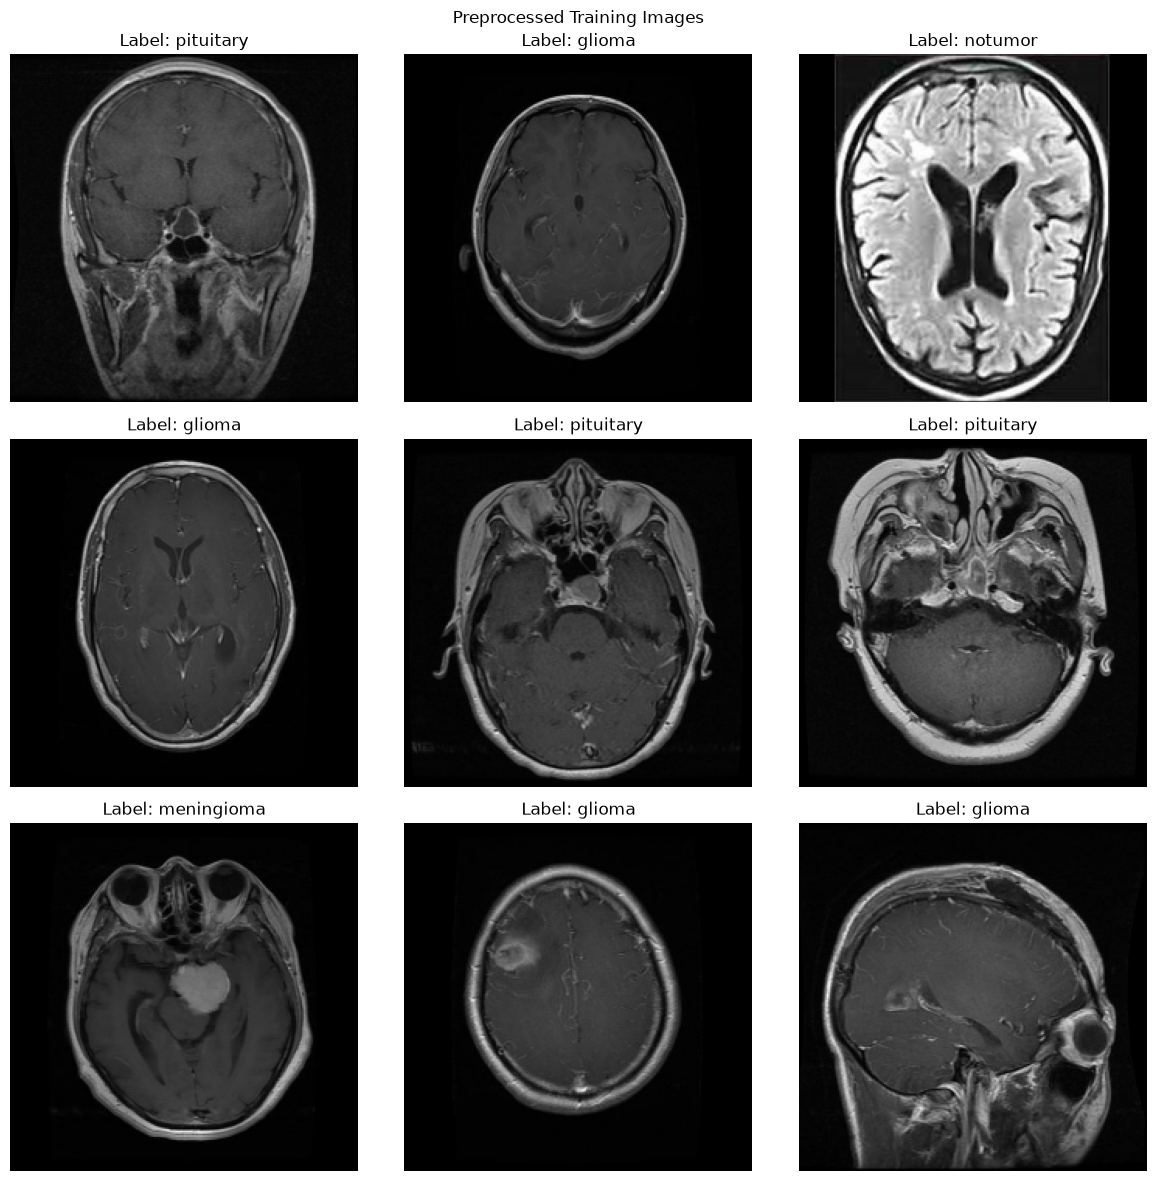

In [18]:
visualize_preprocessed_images(train_ds, class_names)

## 9. Training-Only Data Augmentation

Apply augmentation only to the training dataset and prefetch all datasets.

In [19]:
train_ds, val_ds, test_ds = augment_datasets(train_ds, val_ds, test_ds)

## 10. Validate Final Dataset Readiness

Check dataset sizes, tensor properties, normalized ranges, and valid class labels.

In [20]:
dataset_counts = validate_dataset_readiness(
    train_raw,
    val_raw,
    test_raw,
    val_ds,
    class_names,
)

print("Available datasets: train_ds, val_ds, test_ds")
print("Class mapping:", class_mapping)

2026-10-29 09:21:15.288254: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Train images: 4693
Validation images: 828
Test images: 1205
All dataset readiness checks passed.
Available datasets: train_ds, val_ds, test_ds
Class mapping: {0: 'glioma', 1: 'meningioma', 2: 'notumor', 3: 'pituitary'}
